# U.S. Semiconductor Trade and Production Analysis

## Final Project

**Research Question:** How have U.S. imports and exports of semiconductor devices and integrated circuits changed over time, and what do those trends show about the U.S. semiconductor market?

**Data Sources:** U.S. Census International Trade API and Federal Reserve Economic Data (FRED).

In [1]:
# Import the tools we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Make notebook tables and charts easier to read
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid")

In [2]:
# Create a folder to keep the raw data file organized
from pathlib import Path

DATA_FOLDER = Path("data")
DATA_FOLDER.mkdir(exist_ok=True)

# This is the CSV file required for the final-project submission
TRADE_FILE = DATA_FOLDER / "us_semiconductor_trade_2025_2026.csv"

print(f"Trade data will be saved here: {TRADE_FILE}")

Trade data will be saved here: data\us_semiconductor_trade_2025_2026.csv


In [3]:
# Load the saved Census trade data from the project's data folder

raw_trade_data = pd.read_csv(
    TRADE_FILE,
    parse_dates=["month"]
)

# Keep HS product codes as text labels so they match later chart filters
raw_trade_data["hs_code"] = raw_trade_data["hs_code"].astype(str)

print(f"Loaded {len(raw_trade_data):,} saved Census trade records.")
raw_trade_data.head()

Loaded 10,980 saved Census trade records.


,month,trade_flow,hs_code,product_category,CTY_CODE,CTY_NAME,trade_value_usd
0,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5330,INDIA,80181193
1,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5360,NEPAL,8590
2,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5380,BANGLADESH,697776
3,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5490,THAILAND,37155019
4,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5520,VIETNAM,114405737


In [4]:
# Show each unique Census partner label and its matching code
partner_list = (
    raw_trade_data[["CTY_CODE", "CTY_NAME"]]
    .drop_duplicates()
    .sort_values("CTY_NAME")
)

partner_list

,CTY_CODE,CTY_NAME
2605,5310,AFGHANISTAN
57,7XXX,AFRICA
2117,4810,ALBANIA
218,7210,ALGERIA
105,4271,ANDORRA
...,...,...
193,3070,VENEZUELA
4,5520,VIETNAM
4073,5210,YEMEN
429,7940,ZAMBIA


In [5]:
# Show labels whose codes do NOT look like one real country
not_real_countries = partner_list[
    ~partner_list["CTY_CODE"].astype(str).str.fullmatch(
        r"[1-9]\d{3}",
        na=False
    )
].sort_values("CTY_NAME")

not_real_countries

,CTY_CODE,CTY_NAME
57,7XXX,AFRICA
68,0026,APEC
69,0027,ASEAN
59,5XXX,ASIA
61,6XXX,AUSTRALIA AND OCEANIA
70,0028,CACM
60,0017,CAFTA-DR
75,2XXX,CENTRAL AMERICA
67,0025,EURO AREA
56,4XXX,EUROPE


In [6]:
# Make a clean copy for analysis
trade_data = raw_trade_data.copy()

# Make the country-code column text so Python can check each code
trade_data["CTY_CODE"] = trade_data["CTY_CODE"].astype(str)

# Keep only real individual countries with positive trade values.
# This removes regional group totals and the world total.
trade_data = trade_data[
    trade_data["CTY_CODE"].str.fullmatch(r"[1-9]\d{3}", na=False)
    & (trade_data["trade_value_usd"] > 0)
].copy()

# Make sure month is a real date
trade_data["month"] = pd.to_datetime(trade_data["month"])

# Quick check: only real country rows should remain
print("Clean country-level rows:", f"{len(trade_data):,}")
print(
    "Non-country rows still left:",
    (~trade_data["CTY_CODE"].str.fullmatch(r"[1-9]\d{3}", na=False)).sum()
)

trade_data.head()

Clean country-level rows: 7,061
Non-country rows still left: 0


,month,trade_flow,hs_code,product_category,CTY_CODE,CTY_NAME,trade_value_usd
0,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5330,INDIA,80181193
1,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5360,NEPAL,8590
2,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5380,BANGLADESH,697776
3,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5490,THAILAND,37155019
4,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),5520,VIETNAM,114405737


In [7]:
# Get Census's official "TOTAL FOR ALL COUNTRIES" rows
official_total_rows = raw_trade_data[
    raw_trade_data["CTY_CODE"].astype(str) == "-"
].copy()

# Add up Census's official totals for each month, trade flow, and product code
census_totals = (
    official_total_rows
    .groupby(["month", "trade_flow", "hs_code"], as_index=False)["trade_value_usd"]
    .sum()
    .rename(columns={"trade_value_usd": "census_total_usd"})
)

# Add up our cleaned individual-country rows in the same way
cleaned_totals = (
    trade_data
    .groupby(["month", "trade_flow", "hs_code"], as_index=False)["trade_value_usd"]
    .sum()
    .rename(columns={"trade_value_usd": "cleaned_total_usd"})
)

# Put the two answers beside each other
total_check = cleaned_totals.merge(
    census_totals,
    on=["month", "trade_flow", "hs_code"],
    how="left"
)

# Calculate the difference between our total and Census's total
total_check["difference_usd"] = (
    total_check["cleaned_total_usd"] - total_check["census_total_usd"]
)

print("Largest difference:", f"${total_check['difference_usd'].abs().max():,.0f}")

total_check.head(10)

Largest difference: $0


,month,trade_flow,hs_code,cleaned_total_usd,census_total_usd,difference_usd
0,2025-01-01,Exports,8541,520759916,520759916,0
1,2025-01-01,Exports,8542,4949314274,4949314274,0
2,2025-01-01,Imports,8541,869325116,869325116,0
3,2025-01-01,Imports,8542,3510044541,3510044541,0
4,2025-02-01,Exports,8541,510415669,510415669,0
5,2025-02-01,Exports,8542,3983996259,3983996259,0
6,2025-02-01,Imports,8541,1012823445,1012823445,0
7,2025-02-01,Imports,8542,2879905678,2879905678,0
8,2025-03-01,Exports,8541,503138248,503138248,0
9,2025-03-01,Exports,8542,4382050894,4382050894,0


In [8]:
# Show Census's official total rows from the original raw file
census_total_rows = raw_trade_data[
    raw_trade_data["CTY_CODE"].astype(str) == "-"
][
    [
        "month",
        "trade_flow",
        "hs_code",
        "CTY_CODE",
        "CTY_NAME",
        "trade_value_usd"
    ]
]

census_total_rows.head()

,month,trade_flow,hs_code,CTY_CODE,CTY_NAME,trade_value_usd
53,2025-01-01,Imports,8541,-,TOTAL FOR ALL COUNTRIES,869325116
135,2025-01-01,Imports,8542,-,TOTAL FOR ALL COUNTRIES,3510044541
261,2025-01-01,Exports,8541,-,TOTAL FOR ALL COUNTRIES,520759916
394,2025-01-01,Exports,8542,-,TOTAL FOR ALL COUNTRIES,4949314274
489,2025-02-01,Imports,8541,-,TOTAL FOR ALL COUNTRIES,1012823445


In [9]:
# Summarize country-level trade into monthly U.S. trade totals
monthly_trade = (
    trade_data
    .groupby(
        ["month", "trade_flow", "hs_code", "product_category"],
        as_index=False
    )
    .agg(
        total_trade_value_usd=("trade_value_usd", "sum"),
        average_partner_trade_value_usd=("trade_value_usd", "mean"),
        number_of_partners=("CTY_NAME", "nunique")
    )
)

# Change total values into billions of dollars for easier reading
monthly_trade["total_trade_billions"] = (
    monthly_trade["total_trade_value_usd"] / 1_000_000_000
)

monthly_trade.head(8)

,month,trade_flow,hs_code,product_category,total_trade_value_usd,average_partner_trade_value_usd,number_of_partners,total_trade_billions
0,2025-01-01,Exports,8541,Semiconductor Devices (HS 8541),520759916,"4,528,347.10",115,0.52
1,2025-01-01,Exports,8542,Integrated Circuits (HS 8542),4949314274,"43,415,037.49",114,4.95
2,2025-01-01,Imports,8541,Semiconductor Devices (HS 8541),869325116,"15,523,662.79",56,0.87
3,2025-01-01,Imports,8542,Integrated Circuits (HS 8542),3510044541,"52,388,724.49",67,3.51
4,2025-02-01,Exports,8541,Semiconductor Devices (HS 8541),510415669,"4,516,952.82",113,0.51
5,2025-02-01,Exports,8542,Integrated Circuits (HS 8542),3983996259,"35,891,858.19",111,3.98
6,2025-02-01,Imports,8541,Semiconductor Devices (HS 8541),1012823445,"18,086,132.95",56,1.01
7,2025-02-01,Imports,8542,Integrated Circuits (HS 8542),2879905678,"45,712,788.54",63,2.88


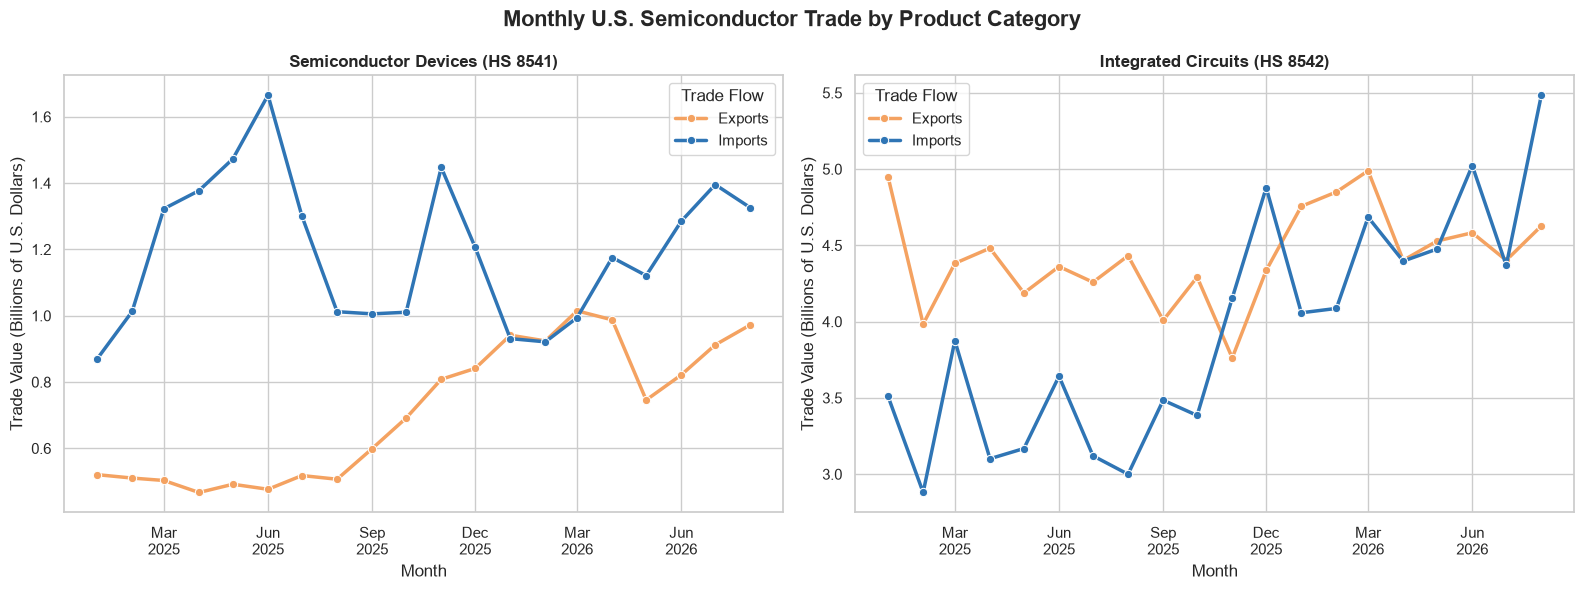

In [10]:
# Chart 1: Compare monthly U.S. imports and exports over time

import matplotlib.dates as mdates

# Names to display above each chart
product_titles = {
    "8541": "Semiconductor Devices (HS 8541)",
    "8542": "Integrated Circuits (HS 8542)"
}

# Colors for imports and exports
colors = {
    "Imports": "#2F75B5",
    "Exports": "#F4A261"
}

# Make two charts side by side:
# one for HS 8541 and one for HS 8542
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for axis, hs_code in zip(axes, ["8541", "8542"]):
    
    # Keep only the rows for the current product category
    chart_data = monthly_trade[
        monthly_trade["hs_code"] == hs_code
    ].copy()
    
    # Draw one line for imports and one line for exports
    sns.lineplot(
        data=chart_data,
        x="month",
        y="total_trade_billions",
        hue="trade_flow",
        palette=colors,
        marker="o",
        linewidth=2.5,
        ax=axis
    )
    
    # Label this individual chart
    axis.set_title(product_titles[hs_code], fontweight="bold")
    axis.set_xlabel("Month")
    axis.set_ylabel("Trade Value (Billions of U.S. Dollars)")
    
    # Show fewer date labels so they are easier to read
    axis.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    
    # Keep the imports/exports key
    axis.legend(title="Trade Flow")

# Main title above both charts
fig.suptitle(
    "Monthly U.S. Semiconductor Trade by Product Category",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [11]:
# Statistical summary of monthly trade values

summary_statistics = (
    monthly_trade
    .groupby(["trade_flow", "product_category"], as_index=False)
    .agg(
        average_monthly_trade_billions=(
            "total_trade_billions", "mean"
        ),
        lowest_monthly_trade_billions=(
            "total_trade_billions", "min"
        ),
        highest_monthly_trade_billions=(
            "total_trade_billions", "max"
        )
    )
)

# Round the numbers so the table is easier to read
summary_statistics = summary_statistics.round(2)

summary_statistics

,trade_flow,product_category,average_monthly_trade_billions,lowest_monthly_trade_billions,highest_monthly_trade_billions
0,Exports,Integrated Circuits (HS 8542),4.43,3.76,4.99
1,Exports,Semiconductor Devices (HS 8541),0.71,0.47,1.01
2,Imports,Integrated Circuits (HS 8542),3.94,2.88,5.48
3,Imports,Semiconductor Devices (HS 8541),1.19,0.87,1.67


In [12]:
# Compare the first month and last month in our data

# Find the earliest and latest months in the dataset
first_month = monthly_trade["month"].min()
last_month = monthly_trade["month"].max()

# Get the trade totals from the first month
first_month_values = (
    monthly_trade[monthly_trade["month"] == first_month]
    [["trade_flow", "hs_code", "product_category", "total_trade_billions"]]
    .rename(columns={"total_trade_billions": "first_month_trade_billions"})
)

# Get the trade totals from the last month
last_month_values = (
    monthly_trade[monthly_trade["month"] == last_month]
    [["trade_flow", "hs_code", "product_category", "total_trade_billions"]]
    .rename(columns={"total_trade_billions": "last_month_trade_billions"})
)

# Match each category's first-month value with its last-month value
trade_change = first_month_values.merge(
    last_month_values,
    on=["trade_flow", "hs_code", "product_category"]
)

# Calculate how much trade changed as a percentage
trade_change["percent_change"] = (
    (
        trade_change["last_month_trade_billions"]
        - trade_change["first_month_trade_billions"]
    )
    / trade_change["first_month_trade_billions"]
) * 100

# Round values so the table is easy to read
trade_change = trade_change.round(2)

trade_change

,trade_flow,hs_code,product_category,first_month_trade_billions,last_month_trade_billions,percent_change
0,Exports,8541,Semiconductor Devices (HS 8541),0.52,0.97,86.74
1,Exports,8542,Integrated Circuits (HS 8542),4.95,4.63,-6.50
2,Imports,8541,Semiconductor Devices (HS 8541),0.87,1.33,52.50
3,Imports,8542,Integrated Circuits (HS 8542),3.51,5.48,56.25


In [13]:
# Load the saved FRED production data from the project's data folder

production_file = DATA_FOLDER / "us_semiconductor_production_index.csv"

production_data = pd.read_csv(
    production_file,
    parse_dates=["date"]
)

print(f"Loaded {len(production_data):,} saved production records.")
production_data.tail()

Loaded 656 saved production records.


,date,production_index
651,2026-04-01,176.69
652,2026-05-01,184.19
653,2026-06-01,187.52
654,2026-07-01,190.26
655,2026-08-01,190.10


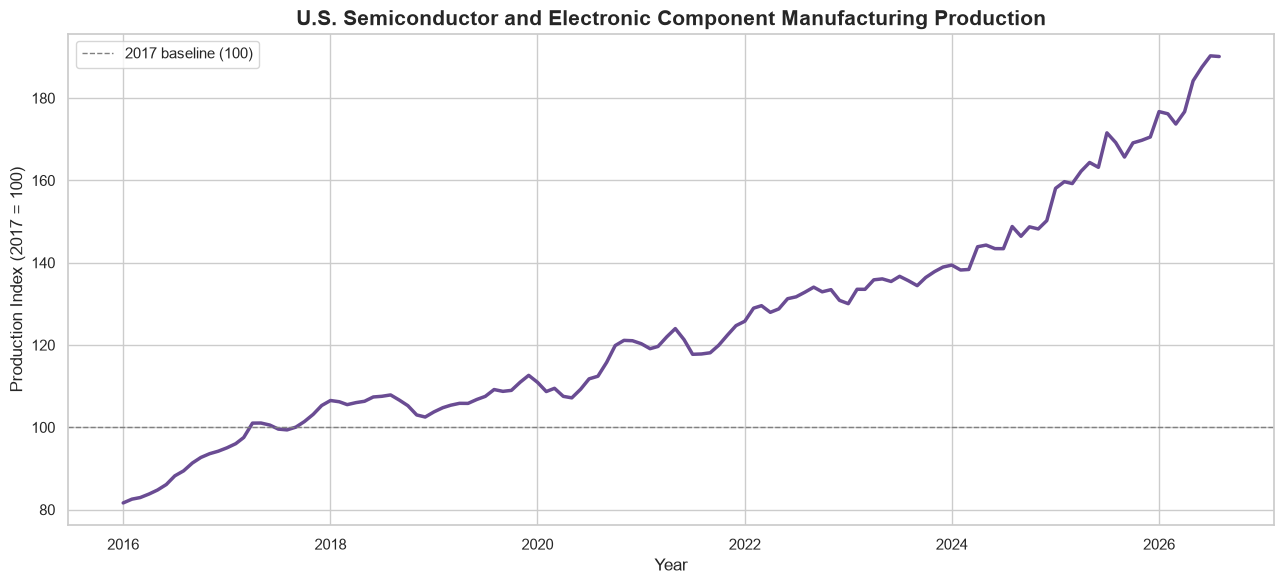

In [14]:
# Chart 2: U.S. semiconductor and electronic component production over time

import matplotlib.dates as mdates

# Use the most recent 10 years so the trend is easier to see
recent_production = production_data[
    production_data["date"] >= "2016-01-01"
].copy()

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=recent_production,
    x="date",
    y="production_index",
    color="#6A4C93",
    linewidth=2.5
)

# The index is based on 2017 = 100
plt.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="2017 baseline (100)"
)

plt.title(
    "U.S. Semiconductor and Electronic Component Manufacturing Production",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Production Index (2017 = 100)")
plt.legend()

plt.gca().xaxis.set_major_locator(mdates.YearLocator(base=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

In [15]:
# Compare the same eight months in each year:
# January–August 2025 versus January–August 2026

# Keep only January through August for both years
production_jan_aug = production_data[
    (production_data["date"].dt.year.isin([2025, 2026])) &
    (production_data["date"].dt.month <= 8)
].copy()

# Add a column that tells us which year each row belongs to
production_jan_aug["year"] = production_jan_aug["date"].dt.year

# Find the average production score for each eight-month period
production_year_comparison = (
    production_jan_aug
    .groupby("year", as_index=False)
    .agg(
        average_production_index=("production_index", "mean")
    )
)

# Pull out each year's average so we can compare them
production_2025 = production_year_comparison.loc[
    production_year_comparison["year"] == 2025,
    "average_production_index"
].iloc[0]

production_2026 = production_year_comparison.loc[
    production_year_comparison["year"] == 2026,
    "average_production_index"
].iloc[0]

# Calculate the percent change from 2025 to 2026
production_percent_change = (
    (production_2026 - production_2025) / production_2025
) * 100

# Round the table so it is easier to read
production_year_comparison["average_production_index"] = (
    production_year_comparison["average_production_index"].round(2)
)

display(production_year_comparison)

print(
    f"Average production index changed from {production_2025:.2f} "
    f"in January–August 2025 to {production_2026:.2f} "
    f"in January–August 2026."
)

print(f"That is a {production_percent_change:.2f}% change.")

,year,average_production_index
0,2025,163.44
1,2026,181.92


Average production index changed from 163.44 in January–August 2025 to 181.92 in January–August 2026.
That is a 11.31% change.


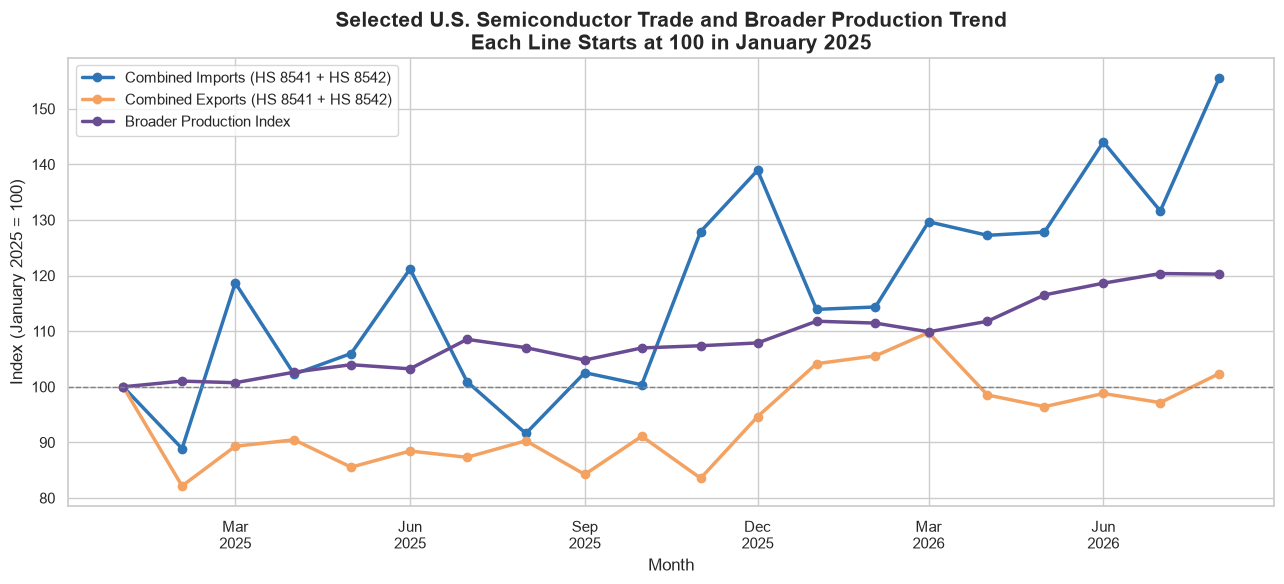

In [16]:
# Compare selected semiconductor trade and broader production over time
# Each line will start at 100 in January 2025

import matplotlib.dates as mdates

# Keep the 20 monthly trade observations from January 2025 to August 2026
trade_for_comparison = monthly_trade[
    monthly_trade["month"].between("2025-01-01", "2026-08-01")
].copy()

# Add HS 8541 and HS 8542 together for each month and trade flow
combined_trade_by_month = (
    trade_for_comparison
    .groupby(["month", "trade_flow"], as_index=False)
    .agg(
        trade_billions=("total_trade_billions", "sum")
    )
)

# Put Imports and Exports into separate columns
combined_trade_wide = (
    combined_trade_by_month
    .pivot(
        index="month",
        columns="trade_flow",
        values="trade_billions"
    )
    .reset_index()
)

# Keep production data for the same 20 months
production_for_comparison = production_data[
    production_data["date"].between("2025-01-01", "2026-08-01")
][["date", "production_index"]].copy()

# Rename date to month so Python can match the two tables
production_for_comparison = production_for_comparison.rename(
    columns={"date": "month"}
)

# Match each month's imports, exports, and production score together
comparison_data = combined_trade_wide.merge(
    production_for_comparison,
    on="month",
    how="inner"
).sort_values("month")

# January 2025 is the starting point: 100 for every line
comparison_data["imports_indexed"] = (
    comparison_data["Imports"] / comparison_data["Imports"].iloc[0] * 100
)

comparison_data["exports_indexed"] = (
    comparison_data["Exports"] / comparison_data["Exports"].iloc[0] * 100
)

comparison_data["production_indexed"] = (
    comparison_data["production_index"]
    / comparison_data["production_index"].iloc[0]
    * 100
)

# Create the comparison chart
plt.figure(figsize=(13, 6))

plt.plot(
    comparison_data["month"],
    comparison_data["imports_indexed"],
    label="Combined Imports (HS 8541 + HS 8542)",
    color="#2F75B5",
    linewidth=2.5,
    marker="o"
)

plt.plot(
    comparison_data["month"],
    comparison_data["exports_indexed"],
    label="Combined Exports (HS 8541 + HS 8542)",
    color="#F4A261",
    linewidth=2.5,
    marker="o"
)

plt.plot(
    comparison_data["month"],
    comparison_data["production_indexed"],
    label="Broader Production Index",
    color="#6A4C93",
    linewidth=2.5,
    marker="o"
)

# Show where all three lines began
plt.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Selected U.S. Semiconductor Trade and Broader Production Trend\n"
    "Each Line Starts at 100 in January 2025",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Index (January 2025 = 100)")
plt.legend()

plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

plt.tight_layout()
plt.show()

### Trade and Production Comparison

When combined imports, combined exports, and the broader production index are all set to 100 in January 2025, imports increase more sharply than production through August 2026. Production rises more steadily, while exports fluctuate and end close to their January 2025 level.

This chart describes patterns in the data only. It does not prove that changes in production caused changes in trade. Trade results cover HS 8541 semiconductor devices and HS 8542 integrated circuits, while the FRED index represents a broader semiconductor and electronic-component manufacturing industry.

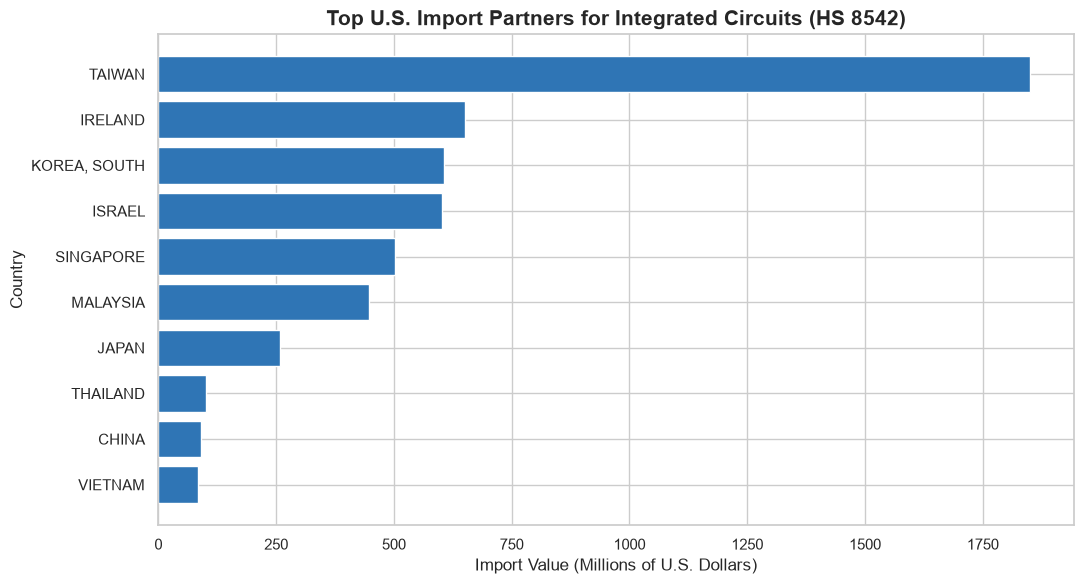

In [17]:
# Chart 3: Top U.S. import partners for integrated circuits
# Using the most recent month in the dataset

latest_month = trade_data["month"].max()

# Keep only August 2026 imports of integrated circuits
latest_integrated_circuit_imports = trade_data[
    (trade_data["month"] == latest_month) &
    (trade_data["trade_flow"] == "Imports") &
    (trade_data["hs_code"] == "8542")
].copy()

# Add each country's import value together, then keep the top 10
top_import_partners_8542 = (
    latest_integrated_circuit_imports
    .groupby("CTY_NAME", as_index=False)["trade_value_usd"]
    .sum()
    .sort_values("trade_value_usd", ascending=False)
    .head(10)
)

# Change dollars into millions to make the chart easier to read
top_import_partners_8542["import_value_millions"] = (
    top_import_partners_8542["trade_value_usd"] / 1_000_000
)

# Make the horizontal bar chart
plt.figure(figsize=(11, 6))

plt.barh(
    top_import_partners_8542["CTY_NAME"],
    top_import_partners_8542["import_value_millions"],
    color="#2F75B5"
)

plt.gca().invert_yaxis()

plt.title(
    "Top U.S. Import Partners for Integrated Circuits (HS 8542)",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Import Value (Millions of U.S. Dollars)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

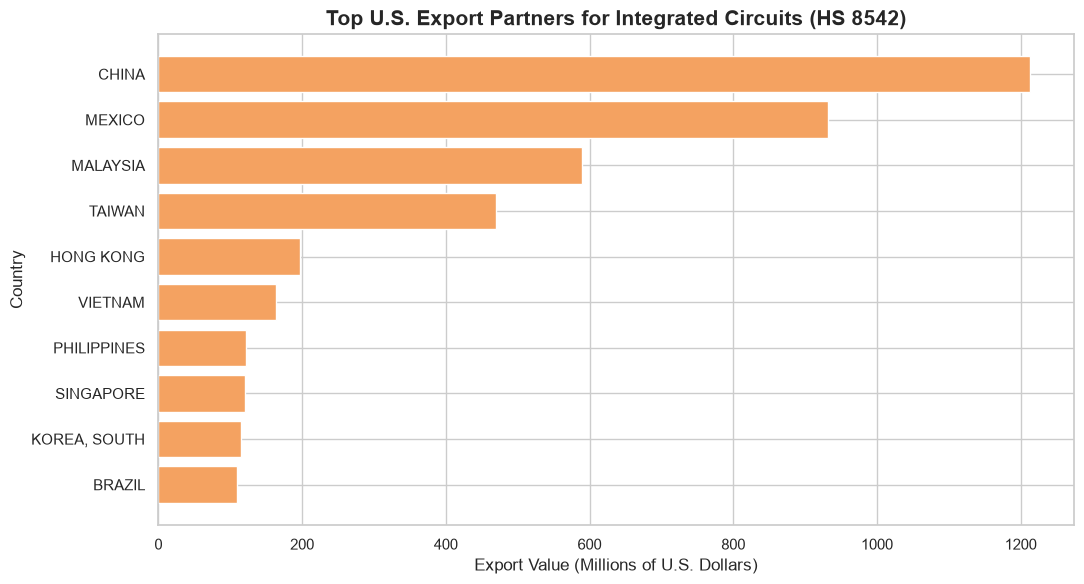

In [18]:
# Chart 4: Top U.S. export partners for integrated circuits
# Using the most recent month in the dataset

# Keep only August 2026 exports of integrated circuits
latest_integrated_circuit_exports = trade_data[
    (trade_data["month"] == latest_month) &
    (trade_data["trade_flow"] == "Exports") &
    (trade_data["hs_code"] == "8542")
].copy()

# Add each country's export value together, then keep the top 10
top_export_partners_8542 = (
    latest_integrated_circuit_exports
    .groupby("CTY_NAME", as_index=False)["trade_value_usd"]
    .sum()
    .sort_values("trade_value_usd", ascending=False)
    .head(10)
)

# Change dollars into millions to make the chart easier to read
top_export_partners_8542["export_value_millions"] = (
    top_export_partners_8542["trade_value_usd"] / 1_000_000
)

# Make the horizontal bar chart
plt.figure(figsize=(11, 6))

plt.barh(
    top_export_partners_8542["CTY_NAME"],
    top_export_partners_8542["export_value_millions"],
    color="#F4A261"
)

plt.gca().invert_yaxis()

plt.title(
    "Top U.S. Export Partners for Integrated Circuits (HS 8542)",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Export Value (Millions of U.S. Dollars)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [19]:
# Show the exact values behind the export-partner chart
export_partner_values = top_export_partners_8542.copy()

# Change dollars into billions so the numbers are easier to read
export_partner_values["export_value_billions"] = (
    export_partner_values["trade_value_usd"] / 1_000_000_000
)

export_partner_values[
    ["CTY_NAME", "export_value_billions"]
].round(2)

,CTY_NAME,export_value_billions
20,CHINA,1.21
65,MEXICO,0.93
63,MALAYSIA,0.59
96,TAIWAN,0.47
42,HONG KONG,0.20
108,VIETNAM,0.16
78,PHILIPPINES,0.12
86,SINGAPORE,0.12
56,"KOREA, SOUTH",0.12
12,BRAZIL,0.11


In [20]:
# Latest-month trade balance by product category
# Trade balance = exports minus imports

latest_trade_summary = (
    monthly_trade[monthly_trade["month"] == latest_month]
    .pivot_table(
        index=["hs_code", "product_category"],
        columns="trade_flow",
        values="total_trade_billions",
        aggfunc="sum"
    )
    .reset_index()
)

# Calculate exports minus imports
latest_trade_summary["trade_balance_billions"] = (
    latest_trade_summary["Exports"]
    - latest_trade_summary["Imports"]
)

# Round the numbers for readability
latest_trade_summary = latest_trade_summary.round(2)

latest_trade_summary

trade_flow,hs_code,product_category,Exports,Imports,trade_balance_billions
0,8541,Semiconductor Devices (HS 8541),0.97,1.33,-0.35
1,8542,Integrated Circuits (HS 8542),4.63,5.48,-0.86


In [21]:
# Add HS 8541 and HS 8542 together for each month
combined_monthly_trade = (
    monthly_trade
    .groupby(["month", "trade_flow"], as_index=False)["total_trade_billions"]
    .sum()
    .pivot(
        index="month",
        columns="trade_flow",
        values="total_trade_billions"
    )
    .reset_index()
)

# Exports minus imports tells us whether that month was a surplus or deficit
combined_monthly_trade["trade_balance_billions"] = (
    combined_monthly_trade["Exports"]
    - combined_monthly_trade["Imports"]
)

# Give each month a simple label
combined_monthly_trade["result"] = np.where(
    combined_monthly_trade["trade_balance_billions"] > 0,
    "Surplus",
    "Deficit"
)

# Count the number of surplus and deficit months
print(combined_monthly_trade["result"].value_counts())

# Show the month-by-month results
combined_monthly_trade.round(
    {
        "Exports": 2,
        "Imports": 2,
        "trade_balance_billions": 2
    }
)

result
Surplus    11
Deficit     9
Name: count, dtype: int64


trade_flow,month,Exports,Imports,trade_balance_billions,result
0,2025-01-01,5.47,4.38,1.09,Surplus
1,2025-02-01,4.49,3.89,0.60,Surplus
2,2025-03-01,4.89,5.20,-0.31,Deficit
3,2025-04-01,4.95,4.48,0.47,Surplus
4,2025-05-01,4.68,4.64,0.04,Surplus
5,2025-06-01,4.84,5.31,-0.47,Deficit
6,2025-07-01,4.78,4.42,0.36,Surplus
7,2025-08-01,4.94,4.01,0.93,Surplus
8,2025-09-01,4.61,4.49,0.12,Surplus
9,2025-10-01,4.98,4.40,0.59,Surplus


In [22]:
# Keep January through August in both years
same_months = monthly_trade[
    monthly_trade["month"].dt.month <= 8
].copy()

# Create a year column so we can compare 2025 with 2026
same_months["year"] = same_months["month"].dt.year

# Add each product category and trade flow across January–August
same_months_totals = (
    same_months
    .groupby(
        ["year", "trade_flow", "hs_code", "product_category"],
        as_index=False
    )["total_trade_value_usd"]
    .sum()
)

# Change dollars into billions
same_months_totals["total_trade_billions"] = (
    same_months_totals["total_trade_value_usd"] / 1_000_000_000
)

# Put 2025 and 2026 side by side for all four trade categories
fair_comparison = (
    same_months_totals
    .pivot_table(
        index=["trade_flow", "hs_code", "product_category"],
        columns="year",
        values="total_trade_billions",
        aggfunc="sum"
    )
    .reset_index()
    .rename(
        columns={
            2025: "jan_aug_2025_billions",
            2026: "jan_aug_2026_billions"
        }
    )
)

# Calculate the percent change from 2025 to 2026
fair_comparison["percent_change"] = (
    (
        fair_comparison["jan_aug_2026_billions"]
        - fair_comparison["jan_aug_2025_billions"]
    )
    / fair_comparison["jan_aug_2025_billions"]
) * 100

fair_comparison.round(
    {
        "jan_aug_2025_billions": 2,
        "jan_aug_2026_billions": 2,
        "percent_change": 2
    }
)

year,trade_flow,hs_code,product_category,jan_aug_2025_billions,jan_aug_2026_billions,percent_change
0,Exports,8541,Semiconductor Devices (HS 8541),3.99,7.32,83.24
1,Exports,8542,Integrated Circuits (HS 8542),35.04,37.14,6.00
2,Imports,8541,Semiconductor Devices (HS 8541),10.03,9.15,-8.80
3,Imports,8542,Integrated Circuits (HS 8542),26.30,36.58,39.10


In [23]:
# Add both product categories together for January–August of each year
combined_year_comparison = (
    same_months_totals
    .groupby(["year", "trade_flow"], as_index=False)["total_trade_billions"]
    .sum()
    .pivot(
        index="year",
        columns="trade_flow",
        values="total_trade_billions"
    )
    .reset_index()
)

# Exports minus imports = trade balance
combined_year_comparison["trade_balance_billions"] = (
    combined_year_comparison["Exports"]
    - combined_year_comparison["Imports"]
)

combined_year_comparison.round(2)

trade_flow,year,Exports,Imports,trade_balance_billions
0,2025,39.03,36.33,2.70
1,2026,44.46,45.73,-1.27


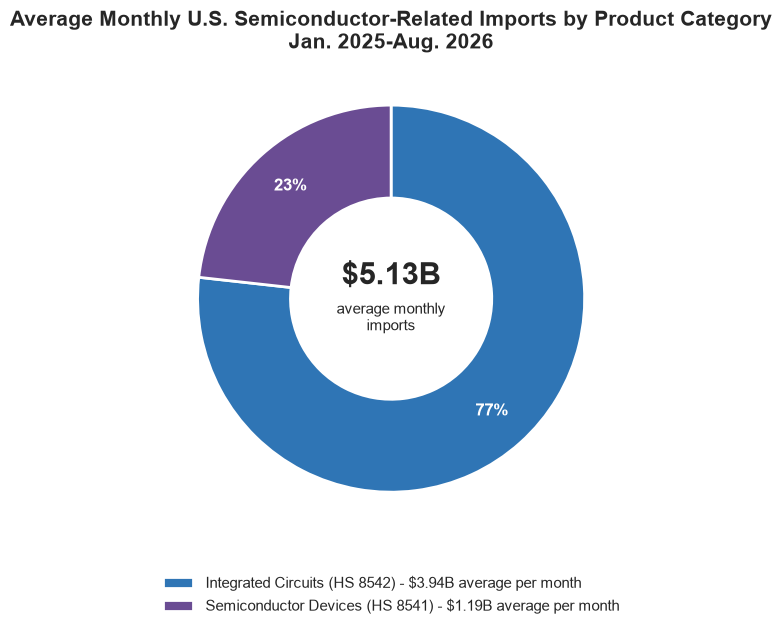

,product_category,total_trade_billions
0,Integrated Circuits (HS 8542),3.94
1,Semiconductor Devices (HS 8541),1.19


In [24]:
# Chart 5: Average monthly U.S. imports by product category (donut chart)
average_monthly_imports = (
    monthly_trade[monthly_trade["trade_flow"] == "Imports"]
    .groupby("product_category", as_index=False)["total_trade_billions"]
    .mean()
    .sort_values("total_trade_billions", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6.5))
wedges, _, percent_labels = ax.pie(
    average_monthly_imports["total_trade_billions"],
    colors=["#2F75B5", "#6A4C93"],
    startangle=90,
    counterclock=False,
    autopct="%1.0f%%",
    pctdistance=0.78,
    wedgeprops={"width": 0.48, "edgecolor": "white", "linewidth": 2},
)
for label in percent_labels:
    label.set_color("white")
    label.set_fontweight("bold")

total_average_imports = average_monthly_imports["total_trade_billions"].sum()
ax.text(0, 0.12, f"${total_average_imports:.2f}B", ha="center", va="center", fontsize=22, fontweight="bold")
ax.text(0, -0.10, "average monthly\nimports", ha="center", va="center", fontsize=11)

legend_labels = [
    f"{row.product_category} - ${row.total_trade_billions:.2f}B average per month"
    for row in average_monthly_imports.itertuples()
]
ax.legend(wedges, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.18), frameon=False)
ax.set_title(
    "Average Monthly U.S. Semiconductor-Related Imports by Product Category\nJan. 2025-Aug. 2026",
    fontsize=15, fontweight="bold",
)
plt.tight_layout()
plt.show()

average_monthly_imports.round(2)


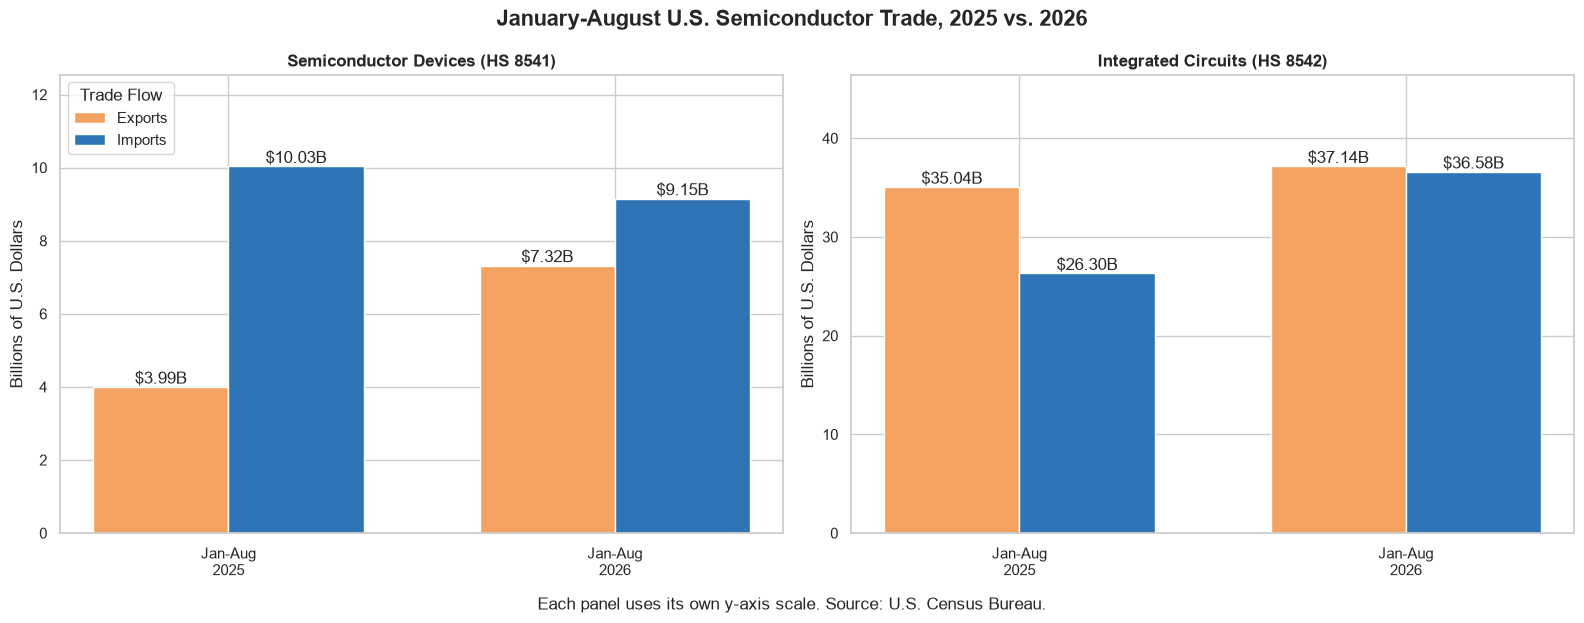

In [25]:
# Chart 6: January-August 2025 vs. January-August 2026 trade by product category
jan_aug = monthly_trade[monthly_trade["month"].dt.month <= 8].copy()
jan_aug["year"] = jan_aug["month"].dt.year
jan_aug_totals = (
    jan_aug.groupby(["product_category", "trade_flow", "year"])["total_trade_billions"]
    .sum()
    .unstack("year")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bar_colors = {"Exports": "#F4A261", "Imports": "#2F75B5"}
bar_width = 0.35
x_positions = np.arange(2)

for axis, category in zip(axes, ["Semiconductor Devices (HS 8541)", "Integrated Circuits (HS 8542)"]):
    for offset, flow in [(-bar_width / 2, "Exports"), (bar_width / 2, "Imports")]:
        values = [jan_aug_totals.loc[(category, flow), 2025], jan_aug_totals.loc[(category, flow), 2026]]
        axis.bar(x_positions + offset, values, bar_width, label=flow, color=bar_colors[flow])
        for x_value, y_value in zip(x_positions + offset, values):
            axis.text(x_value, y_value, f"${y_value:.2f}B", ha="center", va="bottom")
    axis.set_xticks(x_positions)
    axis.set_xticklabels(["Jan-Aug\n2025", "Jan-Aug\n2026"])
    axis.set_title(category, fontweight="bold")
    axis.set_ylabel("Billions of U.S. Dollars")
    axis.set_ylim(0, jan_aug_totals.loc[category].values.max() * 1.25)

axes[0].legend(title="Trade Flow", loc="upper left")
fig.suptitle("January-August U.S. Semiconductor Trade, 2025 vs. 2026", fontsize=16, fontweight="bold")
fig.text(0.5, -0.02, "Each panel uses its own y-axis scale. Source: U.S. Census Bureau.", ha="center")
plt.tight_layout()
plt.show()


## Key Findings

- The broader U.S. semiconductor and electronic-component manufacturing production index rose from the 2017 baseline of 100 to about 190 by August 2026, showing substantial long-term growth in production activity.

- Comparing the same months in each year (January–August), semiconductor-device exports increased from USD 3.99B in 2025 to USD 7.32B in 2026, an increase of 83.24%. Device imports decreased by 8.80% over the same period.

- Integrated-circuit imports increased from USD 26.30B to USD 36.58B, or 39.10%, while integrated-circuit exports increased only 6.00%, from USD 35.04B to USD 37.14B.

- Across both selected product categories, the U.S. trade balance shifted from a USD 2.70B surplus in January–August 2025 to a USD 1.27B deficit in January–August 2026. Across all 20 months, there were 11 surplus months and 9 deficit months; August 2026 had the largest deficit at USD 1.21B.

- Taiwan was the largest reported U.S. import partner for integrated circuits in August 2026, at about USD 1.85B. China was the largest reported U.S. export partner, at about USD 1.21B.

> **Scope note:** These trade findings cover HS 8541 semiconductor devices and HS 8542 integrated circuits, not every type of semiconductor-related product.

## Data Sources

1. **U.S. Census Bureau International Trade API**  
   Used to collect monthly U.S. import and export values by country for:
   - HS 8541: Semiconductor Devices
   - HS 8542: Integrated Circuits  
   
   Source: [U.S. Census Bureau International Trade Data](https://www.census.gov/foreign-trade/reference/guides/Guide_to_International_Trade_Datasets.html)

2. **Federal Reserve Economic Data (FRED)**  
   Used for the Industrial Production: Semiconductor and Other Electronic Component Manufacturing index, series IPG3344S.  
   
   Source: [FRED Series IPG3344S](https://fred.stlouisfed.org/series/IPG3344S)

The downloaded datasets were saved as CSV files in the project's `data` folder:
- `us_semiconductor_trade_2025_2026.csv`
- `us_semiconductor_production_index.csv`